<a href="https://colab.research.google.com/github/Luiz-castilho/CalculoNumerico/blob/main/Sistemas_lineares.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Número de iterações realizadas: 6
Solução aproximada [x, y, z]: [ 1.00000003  1.99999998 -1.00000001]

------------------------
 k    x^(k)    y^(k)     z^(k)  ||x^(k) - x^(k-1)||_inf
 0 0.000000 0.000000  0.000000                      NaN
 1 0.600000 2.054545 -0.914545                 2.054545
 2 0.988364 2.006711 -0.997002                 0.388364
 3 1.000071 2.000279 -0.999986                 0.011708
 4 1.000025 2.000004 -1.000005                 0.000276
 5 1.000001 2.000000 -1.000000                 0.000024
 6 1.000000 2.000000 -1.000000                 0.000001


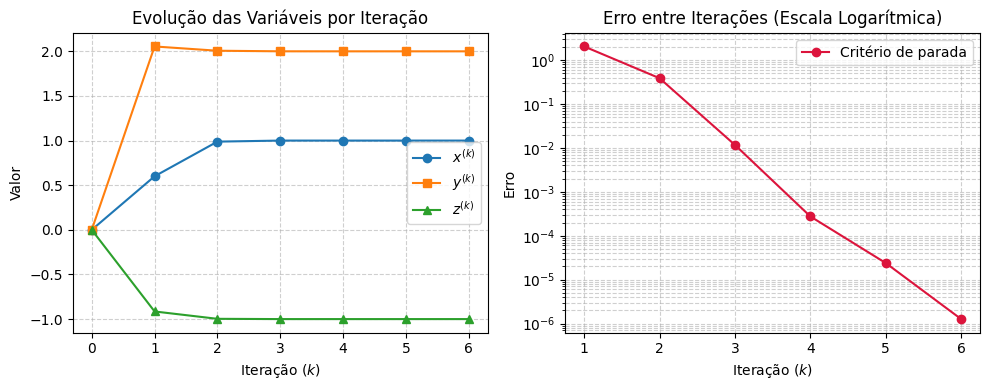

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def gauss_seidel(A, b, x0, tol=1e-5, max_iter=1000):
    x = np.array(x0, dtype=float)
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)

    iteracoes= [[0,x[0], x[1], x[2], np.nan]]

    for k in range(1, max_iter + 1):
        x_novo = np.copy(x)

        for i in range(n):
            soma1 = np.dot(A[i, :i], x_novo[:i])
            soma2 = np.dot(A[i, i+1:], x[i+1:])
            x_novo[i] = (b[i] - soma1 - soma2) / A[i, i]

        #max_i |x_i^(k) - x_i^(k-1)|
        erro = np.max(np.abs(x_novo - x))
        iteracoes.append([k, x_novo[0], x_novo[1], x_novo[2], erro])

        x = x_novo

        if erro < tol:
            break

    return x, k, iteracoes


A = [[10,  -1, 2],
     [ -1, 11, -1],
     [2,  -1, 10]]

b = [6, 22, -10]
x0 = [0, 0, 0]  # Chute inicial padrão


solucao, num_iter, hist = gauss_seidel(A, b, x0, tol=1e-5)


print(f"Número de iterações realizadas: {num_iter}")
print(f"Solução aproximada [x, y, z]: {solucao}\n")


colunas = ["k", "x^(k)", "y^(k)", "z^(k)", "||x^(k) - x^(k-1)||_inf"]
df = pd.DataFrame(hist, columns=colunas)

print("------------------------")
print(df.to_string(index=False))


k_vals = df["k"]
x_vals = df["x^(k)"]
y_vals = df["y^(k)"]
z_vals = df["z^(k)"]
erro_vals = df["||x^(k) - x^(k-1)||_inf"]

# Gráfico -- x^(k), y^(k) e z^(k) vs k
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(k_vals, x_vals, marker='o', label='$x^{(k)}$')
plt.plot(k_vals, y_vals, marker='s', label='$y^{(k)}$')
plt.plot(k_vals, z_vals, marker='^', label='$z^{(k)}$')
plt.title("Evolução das Variáveis por Iteração")
plt.xlabel("Iteração ($k$)")
plt.ylabel("Valor")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

# Gráfico -- Erro entre iterações em escala logarítmica vs k
plt.subplot(1, 2, 2)
# Exclui a iteração 0 (onde o erro é NaN)
plt.semilogy(k_vals[1:], erro_vals[1:], marker='o', color='crimson', label=r'Critério de parada')
plt.title("Erro entre Iterações (Escala Logarítmica)")
plt.xlabel("Iteração ($k$)")
plt.ylabel("Erro")
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

Link para o pdf: https://drive.google.com/drive/folders/1aM1lYOoPTDkJr3KQ8wQNE0Jhe2VBd8ZQ?usp=sharing